# Graphiques

### Comparaison reward DAgger vs RLPD

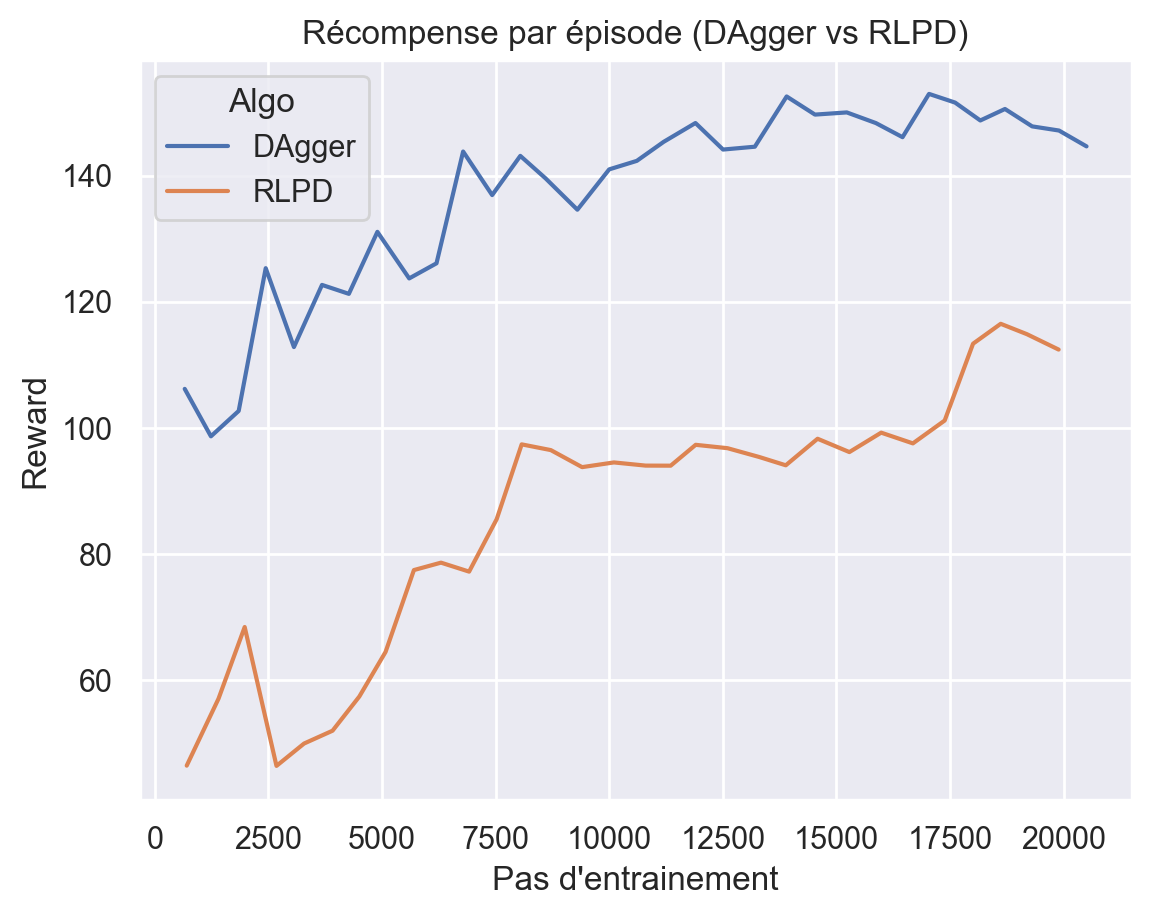

In [95]:
import numpy as np
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

dagger = np.load("logs/metrics_dagger.npz")
rlpd = np.load("logs/metrics_rlpd.npz")

steps_dagger = np.cumsum(dagger["lengths"])
steps_rlpd = np.cumsum(rlpd["lengths"])


df_dagger = pd.DataFrame({
    "Pas d'entrainement": steps_dagger,
    "Reward": pd.Series(dagger["rewards"]).expanding().mean(),
    "Pas par episode": pd.Series(dagger["lengths"]).expanding().mean(),
    "Algo": "DAgger",
})
df_rlpd = pd.DataFrame({
    "Pas d'entrainement":steps_rlpd,
    "Reward": pd.Series(rlpd["rewards"]).expanding().mean(),
    "Pas par episode": pd.Series(rlpd["lengths"]).expanding().mean(),
    "Algo": "RLPD",
})

data = pd.concat([df_dagger, df_rlpd], ignore_index=True)
sn.set_theme(style="darkgrid")

sn.lineplot(data=data, x="Pas d'entrainement", y="Reward", hue="Algo")
plt.title("Récompense par épisode (DAgger vs RLPD)")
plt.show()


### Comparaison Pas Par episode

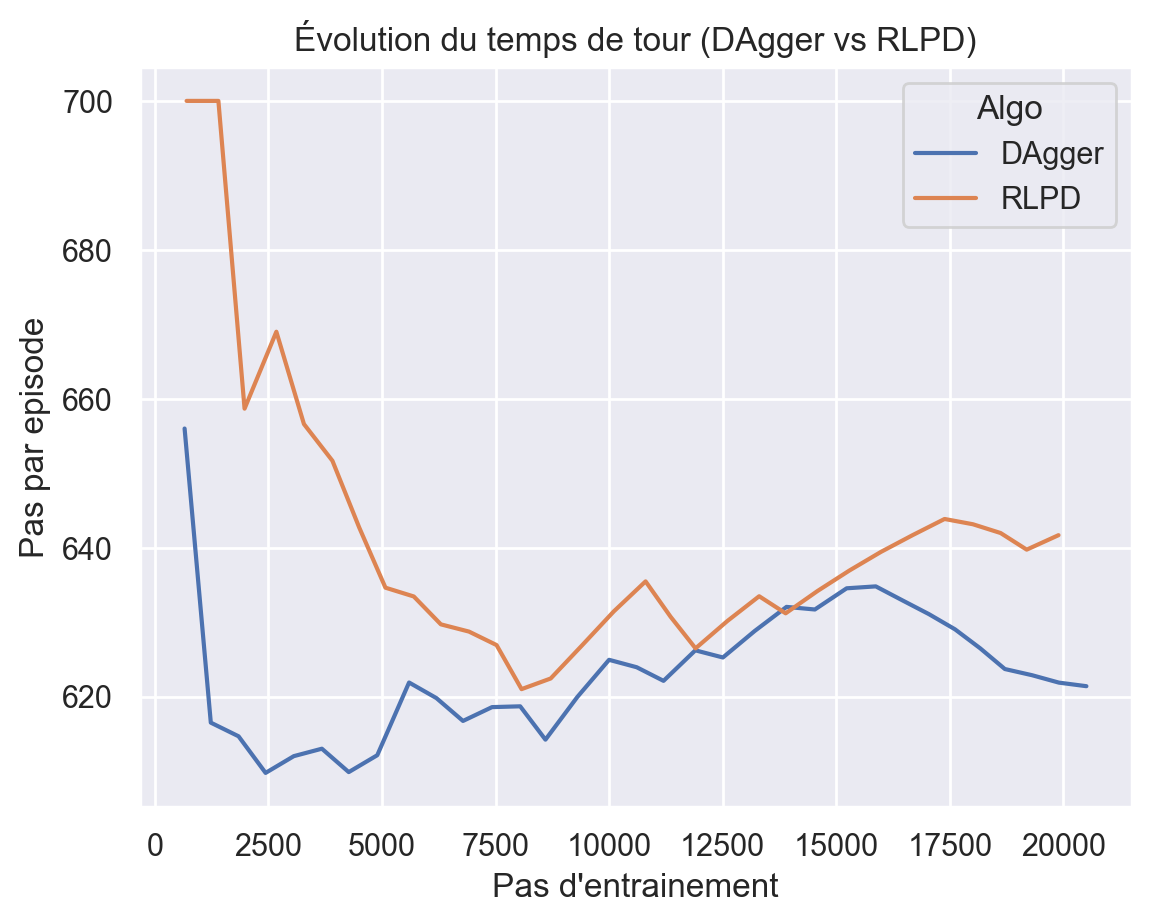

In [90]:
sn.lineplot(data=data, x="Pas d'entrainement", y="Pas par episode", hue="Algo")
plt.title("Évolution du temps de tour (DAgger vs RLPD)")
plt.show()
